Break dates: ['2021-12-13', '2021-12-20', '2022-01-04', '2022-01-19']
Break indices: [12, 19, 34, 49]
Segment bounds: [(0, 12), (12, 19), (19, 34), (34, 49), (49, 63)]


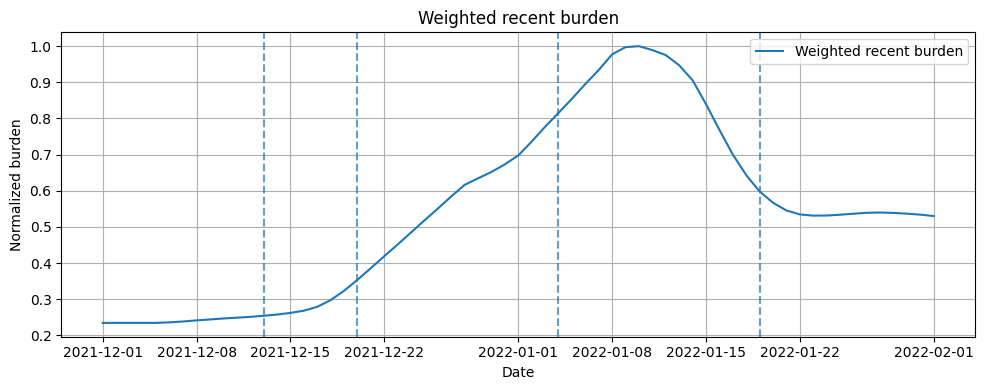

Optimization success: True
Message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH

Final model: mm_weighted_burden
rho = 1.0800271508028423
I0 = 197113.57142914704
gamma = 0.14285714285714285
MSE = 62049878.191268
RMSE = 7877.17450557419
log_MSE = 0.004458933100911325

Segment parameters:
Segment 1: {'beta0': np.float64(0.18579291068503676), 'k': np.float64(0.0), 'h': np.float64(0.23782269064133083)}
Segment 2: {'beta0': np.float64(0.24514480579076445), 'k': np.float64(0.2426255785502091), 'h': np.float64(0.2415808160448071)}
Segment 3: {'beta0': np.float64(0.24815690753062294), 'k': np.float64(0.4345258519613055), 'h': np.float64(0.2917676175107309)}
Segment 4: {'beta0': np.float64(0.20859491281014472), 'k': np.float64(1.3525347679405844), 'h': np.float64(0.8051086959201265)}
Segment 5: {'beta0': np.float64(0.1726653094264005), 'k': np.float64(0.2785527535147344), 'h': np.float64(0.13983578997983293)}


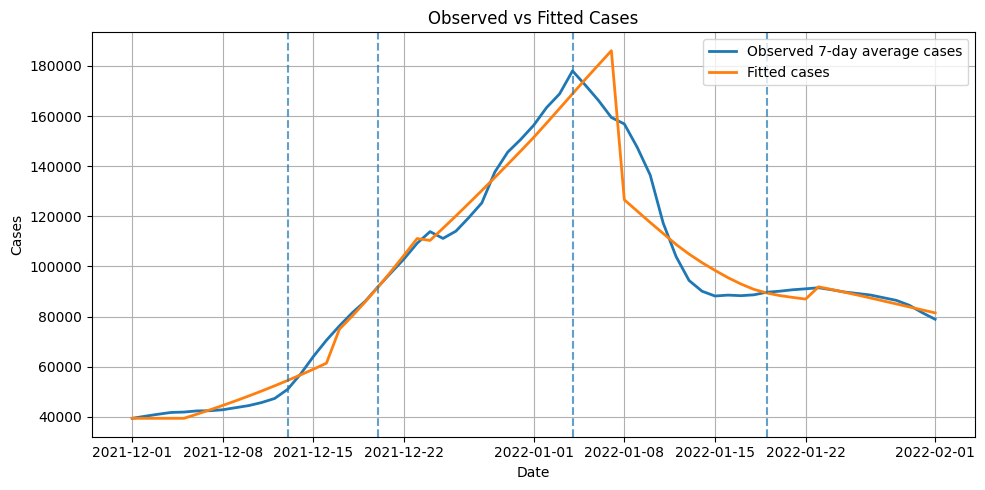

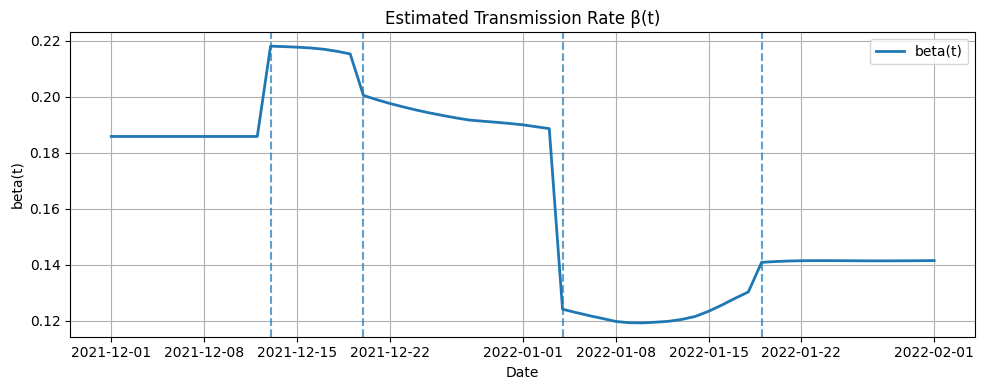


Segment summary:
   segment  start_date    end_date  n_days  beta_start  beta_end  beta_mean  \
0        1  2021-12-01  2021-12-12      12    0.185793  0.185793   0.185793   
1        2  2021-12-13  2021-12-19       7    0.218021  0.215248   0.217044   
2        3  2021-12-20  2022-01-03      15    0.200430  0.188582   0.193349   
3        4  2022-01-04  2022-01-18      15    0.124123  0.130292   0.122448   
4        5  2022-01-19  2022-02-01      14    0.140861  0.141482   0.141362   

   beta_abs_change  beta_pct_change  observed_mean_cases  fitted_mean_cases  \
0         0.000000         0.000000         42785.380952       43594.586255   
1        -0.002773        -1.271815         69536.081633       67560.824635   
2        -0.011847        -5.910927        127234.695238      126733.458413   
3         0.006169         4.969788        125095.752381      125509.771382   
4         0.000621         0.440976         87905.071429       87164.708437   

   model_mean_incidence beta_dir

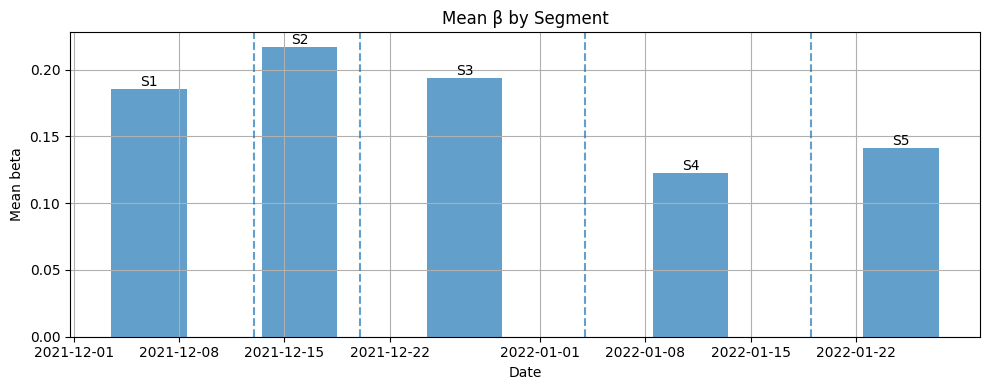


Compact interpretation draft:
Segment 1 (2021-12-01 to 2021-12-12): Pre-Plan B, beta moved from 0.1858 to 0.1858, average 0.1858, which is a roughly flat (0.00% over the segment).
Segment 2 (2021-12-13 to 2021-12-19): Plan B introduced, beta moved from 0.2180 to 0.2152, average 0.2170, which is a decrease (-1.27% over the segment).
Segment 3 (2021-12-20 to 2022-01-03): Omicron-dominant growth, beta moved from 0.2004 to 0.1886, average 0.1933, which is a decrease (-5.91% over the segment).
Segment 4 (2022-01-04 to 2022-01-18): Post-holiday behaviour adjustment, beta moved from 0.1241 to 0.1303, average 0.1224, which is a increase (4.97% over the segment).
Segment 5 (2022-01-19 to 2022-02-01): Plan B relaxation, beta moved from 0.1409 to 0.1415, average 0.1414, which is a increase (0.44% over the segment).


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =========================================================
# 1. load data
# =========================================================
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

# fitting window
df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

dates = pd.to_datetime(df_fit["date"]).reset_index(drop=True)
obs_cases = df_fit["cases_7d"].values.astype(float)
T = len(obs_cases)

# =========================================================
# 2. settings
# =========================================================
N = 67_000_000
gamma_fixed = 1 / 7
tau_fixed = 4
eps = 1.0

MODEL_NAME = "mm_weighted_burden"

# =========================================================
# 3. breakpoints
# =========================================================
break_dates = ["2021-12-13", "2021-12-20", "2022-01-04", "2022-01-19"]

for d in break_dates:
    if pd.Timestamp(d) not in set(df_fit["date"]):
        raise ValueError(f"Breakpoint {d} not found in df_fit.")

break_indices = [
    int(np.where(df_fit["date"] == pd.Timestamp(d))[0][0])
    for d in break_dates
]

def get_segment_bounds(T, break_indices):
    bounds = [0] + break_indices + [T]
    return [(bounds[i], bounds[i + 1]) for i in range(len(bounds) - 1)]

segment_bounds = get_segment_bounds(T, break_indices)
n_seg = len(segment_bounds)

print("Break dates:", break_dates)
print("Break indices:", break_indices)
print("Segment bounds:", segment_bounds)

# =========================================================
# 4. helpers
# =========================================================
def apply_fixed_delay(x, tau):
    tau = int(tau)
    y = np.empty_like(x)
    if tau <= 0:
        return x.copy()
    y[:tau] = x[0]
    y[tau:] = x[:-tau]
    return y

def get_segment_index(t_idx, segment_bounds):
    for j, (a, b) in enumerate(segment_bounds):
        if a <= t_idx < b:
            return j
    return len(segment_bounds) - 1

# =========================================================
# 5. build weighted recent burden
#    using previous 7 days with linear weights
# =========================================================
L = 7  # look-back window

# observed proxy with reporting delay
obs_proxy = apply_fixed_delay(obs_cases, tau_fixed)

# linear weights: most recent gets largest weight
# ell = 0 means today, ell = 1 means yesterday, ...
lam = 0.75
raw_weights = np.array([lam**ell for ell in range(L)])
raw_weights = raw_weights / raw_weights.sum()

weighted_burden = np.zeros(T)

for t in range(T):
    vals = []
    wts = []

    for ell in range(L):
        idx = t - ell
        if idx >= 0:
            vals.append(obs_proxy[idx])
            wts.append(raw_weights[ell])

    vals = np.array(vals, dtype=float)
    wts = np.array(wts, dtype=float)
    wts = wts / wts.sum()

    weighted_burden[t] = np.sum(wts * vals)

# normalize to [0,1]
denom = np.max(weighted_burden)
if denom <= 0:
    denom = 1.0
weighted_burden = weighted_burden / denom

# optional: inspect burden
plt.figure(figsize=(10, 4))
plt.plot(dates, weighted_burden, label="Weighted recent burden")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--", alpha=0.7)
plt.title("Weighted recent burden")
plt.xlabel("Date")
plt.ylabel("Normalized burden")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# =========================================================
# 6. beta(t): mm_weighted_burden
#    beta = beta0 / (1 + k * (B / (h + B)))
# =========================================================
def beta_t_value(model_name, t_idx, param_list, burden, segment_bounds):
    seg_idx = get_segment_index(t_idx, segment_bounds)
    B = burden[t_idx]
    p = param_list[seg_idx]

    if model_name == "mm_weighted_burden":
        beta_t = p["beta0"] / (1.0 + p["k"] * (B / (p["h"] + B + 1e-12)))
    else:
        raise ValueError(f"Unknown model: {model_name}")

    return max(1e-8, beta_t)

# =========================================================
# 7. parameter unpacking
# =========================================================
def unpack_theta(model_name, theta, n_seg):
    params = []
    pos = 0

    if model_name == "mm_weighted_burden":
        for _ in range(n_seg):
            params.append({
                "beta0": theta[pos],
                "k": theta[pos + 1],
                "h": theta[pos + 2]
            })
            pos += 3
    else:
        raise ValueError(f"Unknown model: {model_name}")

    rho = theta[pos]
    I0 = theta[pos + 1]

    return params, rho, I0

def make_x0_bounds(model_name, n_seg, first_case):
    x0 = []
    bounds = []

    if model_name == "mm_weighted_burden":
        for _ in range(n_seg):
            x0 += [0.22, 2.0, 0.3]   # beta0, k, h
            bounds += [(1e-6, 1.0), (0.0, 30.0), (0.01, 2.0)]
    else:
        raise ValueError(f"Unknown model: {model_name}")

    # rho, I0
    x0 += [1.0, first_case * 5.0]
    bounds += [(1e-6, 100.0), (1.0, 5_000_000.0)]

    return np.array(x0, dtype=float), bounds

# =========================================================
# 8. discrete-time SIR
# =========================================================
def simulate_discrete_sir(model_name, theta, burden, gamma, N, T, tau, segment_bounds, n_seg):
    params, rho, I0 = unpack_theta(model_name, theta, n_seg)

    if rho <= 0 or I0 <= 0 or I0 >= N:
        raise ValueError("Invalid rho or I0")

    S = np.zeros(T)
    I = np.zeros(T)
    R = np.zeros(T)
    beta_path = np.zeros(T)
    incidence = np.zeros(T)

    S[0] = N - I0
    I[0] = I0
    R[0] = 0.0

    for t in range(T):
        beta_path[t] = beta_t_value(model_name, t, params, burden, segment_bounds)
        incidence[t] = beta_path[t] * S[t] * I[t] / N

        if t < T - 1:
            new_inf = incidence[t]
            new_rec = gamma * I[t]

            S[t + 1] = max(0.0, S[t] - new_inf)
            I[t + 1] = max(0.0, I[t] + new_inf - new_rec)
            R[t + 1] = max(0.0, R[t] + new_rec)

    fitted_cases = rho * apply_fixed_delay(incidence, tau)

    return {
        "S": S,
        "I": I,
        "R": R,
        "beta_path": beta_path,
        "incidence": incidence,
        "fitted_cases": fitted_cases,
        "rho": rho,
        "I0": I0,
        "params": params,
    }

# =========================================================
# 9. loss function
# =========================================================
def regularization_penalty(theta, lam=1e-4):
    return lam * np.sum(theta[:-2] ** 2)

def loss_fn(theta, model_name):
    try:
        sim = simulate_discrete_sir(
            model_name=model_name,
            theta=theta,
            burden=weighted_burden,
            gamma=gamma_fixed,
            N=N,
            T=T,
            tau=tau_fixed,
            segment_bounds=segment_bounds,
            n_seg=n_seg
        )

        fitted = sim["fitted_cases"]

        if np.any(np.isnan(fitted)) or np.any(np.isinf(fitted)):
            return 1e20
        if np.any(fitted < 0):
            return 1e20

        fit_loss = np.mean((np.log(fitted + eps) - np.log(obs_cases + eps)) ** 2)
        reg = regularization_penalty(theta, lam=1e-4)
        return fit_loss + reg

    except Exception:
        return 1e20

# =========================================================
# 10. fit model
# =========================================================
x0, bounds = make_x0_bounds(MODEL_NAME, n_seg, obs_cases[0])

result = minimize(
    loss_fn,
    x0=x0,
    args=(MODEL_NAME,),
    method="L-BFGS-B",
    bounds=bounds,
)

print("Optimization success:", result.success)
print("Message:", result.message)

theta_hat = result.x

best = simulate_discrete_sir(
    model_name=MODEL_NAME,
    theta=theta_hat,
    burden=weighted_burden,
    gamma=gamma_fixed,
    N=N,
    T=T,
    tau=tau_fixed,
    segment_bounds=segment_bounds,
    n_seg=n_seg
)

mse = np.mean((best["fitted_cases"] - obs_cases) ** 2)
rmse = np.sqrt(mse)
log_mse = np.mean((np.log(best["fitted_cases"] + eps) - np.log(obs_cases + eps)) ** 2)

print("\nFinal model:", MODEL_NAME)
print("rho =", best["rho"])
print("I0 =", best["I0"])
print("gamma =", gamma_fixed)
print("MSE =", mse)
print("RMSE =", rmse)
print("log_MSE =", log_mse)

print("\nSegment parameters:")
for j, p in enumerate(best["params"], start=1):
    print(f"Segment {j}: {p}")

# =========================================================
# 11. main plots
# =========================================================
plt.figure(figsize=(10, 5))
plt.plot(dates, obs_cases, linewidth=2, label="Observed 7-day average cases")
plt.plot(dates, best["fitted_cases"], linewidth=2, label="Fitted cases")

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--", alpha=0.7)

plt.title("Observed vs Fitted Cases")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/weighted_cases_fit.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(dates, best["beta_path"], linewidth=2, label="beta(t)")

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--", alpha=0.7)

plt.title("Estimated Transmission Rate β(t)")
plt.xlabel("Date")
plt.ylabel("beta(t)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/weighted_beta_t.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# 12. policy outcome analysis
# =========================================================
beta_path = np.array(best["beta_path"], dtype=float)
fitted_cases = np.array(best["fitted_cases"], dtype=float)
incidence = np.array(best["incidence"], dtype=float)

segment_summary = []

for j, (a, b) in enumerate(segment_bounds):
    beta_seg = beta_path[a:b]
    obs_seg = obs_cases[a:b]
    fit_seg = fitted_cases[a:b]
    inc_seg = incidence[a:b]

    beta_start = float(beta_seg[0])
    beta_end = float(beta_seg[-1])
    beta_mean = float(np.mean(beta_seg))
    beta_abs_change = beta_end - beta_start
    beta_pct_change = 100.0 * (beta_end - beta_start) / beta_start if beta_start != 0 else np.nan

    obs_mean = float(np.mean(obs_seg))
    fit_mean = float(np.mean(fit_seg))
    inc_mean = float(np.mean(inc_seg))

    segment_summary.append({
        "segment": j + 1,
        "start_date": dates.iloc[a].strftime("%Y-%m-%d"),
        "end_date": dates.iloc[b - 1].strftime("%Y-%m-%d"),
        "n_days": b - a,
        "beta_start": beta_start,
        "beta_end": beta_end,
        "beta_mean": beta_mean,
        "beta_abs_change": beta_abs_change,
        "beta_pct_change": beta_pct_change,
        "observed_mean_cases": obs_mean,
        "fitted_mean_cases": fit_mean,
        "model_mean_incidence": inc_mean
    })

seg_df = pd.DataFrame(segment_summary)

def classify_beta_change(x, tol=1e-4):
    if x > tol:
        return "increase"
    elif x < -tol:
        return "decrease"
    return "roughly flat"

seg_df["beta_direction"] = seg_df["beta_abs_change"].apply(classify_beta_change)

event_labels = {
    1: "Pre-Plan B",
    2: "Plan B introduced",
    3: "Omicron-dominant growth",
    4: "Post-holiday behaviour adjustment",
    5: "Plan B relaxation"
}
seg_df["event_label"] = seg_df["segment"].map(event_labels)

print("\nSegment summary:")
print(seg_df)

seg_df.to_csv("../results/weighted_segment_policy_summary.csv", index=False)

# =========================================================
# 13. mean beta by segment
# =========================================================
seg_mid_dates = []
for (a, b) in segment_bounds:
    mid_idx = (a + b - 1) // 2
    seg_mid_dates.append(dates.iloc[mid_idx])

plt.figure(figsize=(10, 4))
plt.bar(seg_mid_dates, seg_df["beta_mean"], width=5, alpha=0.7)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--", alpha=0.7)

for i, row in seg_df.iterrows():
    plt.text(
        seg_mid_dates[i],
        row["beta_mean"],
        f"S{int(row['segment'])}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("Mean β by Segment")
plt.xlabel("Date")
plt.ylabel("Mean beta")
plt.grid()
plt.tight_layout()
plt.savefig("../results/weighted_beta_segment.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# 14. compact interpretation
# =========================================================
print("\nCompact interpretation draft:")
for _, row in seg_df.iterrows():
    print(
        f"Segment {int(row['segment'])} ({row['start_date']} to {row['end_date']}): "
        f"{row['event_label']}, beta moved from {row['beta_start']:.4f} "
        f"to {row['beta_end']:.4f}, average {row['beta_mean']:.4f}, "
        f"which is a {row['beta_direction']} "
        f"({row['beta_pct_change']:.2f}% over the segment)."
    )